# Визуализация результатов

Таблица привлечений по каналам предварительно посчитана в SQL. Результаты должны быть загружены как файл "channel_metrics.csv"  и "seller_concentration.csv" в папку "/content" при работе в Google Colab


In [53]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [54]:
df = pd.read_csv("channel_metrics.csv")

In [55]:
df.head()

,origin,total_leads,deals_30d,cr_lead_to_deal,activated_sellers,cr_lead_to_activation,total_gmv,gmv_per_lead
0,unknown,861,140,16.26,23,2.67,27642,32.10
1,referral,211,15,7.11,5,2.37,3867,18.33
2,paid_search,1182,123,10.41,23,1.95,11353,9.60
3,direct_traffic,380,41,10.79,8,2.11,1491,3.92
4,organic_search,1736,175,10.08,33,1.90,6558,3.78


In [56]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   origin                 10 non-null     object 
 1   total_leads            10 non-null     int64  
 2   deals_30d              10 non-null     int64  
 3   cr_lead_to_deal        10 non-null     float64
 4   activated_sellers      10 non-null     int64  
 5   cr_lead_to_activation  10 non-null     float64
 6   total_gmv              10 non-null     int64  
 7   gmv_per_lead           10 non-null     float64
dtypes: float64(3), int64(4), object(1)
memory usage: 772.0+ bytes


In [57]:
#Проверка соответствия сумм в загруженных данных
print(df[["total_leads", "deals_30d", "activated_sellers", "total_gmv"]].sum())

total_leads           5998
deals_30d              551
activated_sellers       97
total_gmv            52194
dtype: int64


In [58]:
df_sum = df[["total_leads", "deals_30d", "activated_sellers"]].sum()
categories = ['Заявки', 'Договоры', 'Активации']
values = df_sum.values

cr_deal = values[1] / values[0] * 100
cr_activation = values[2] / values[1] * 100
cr_total = values[2] / values[0] * 100


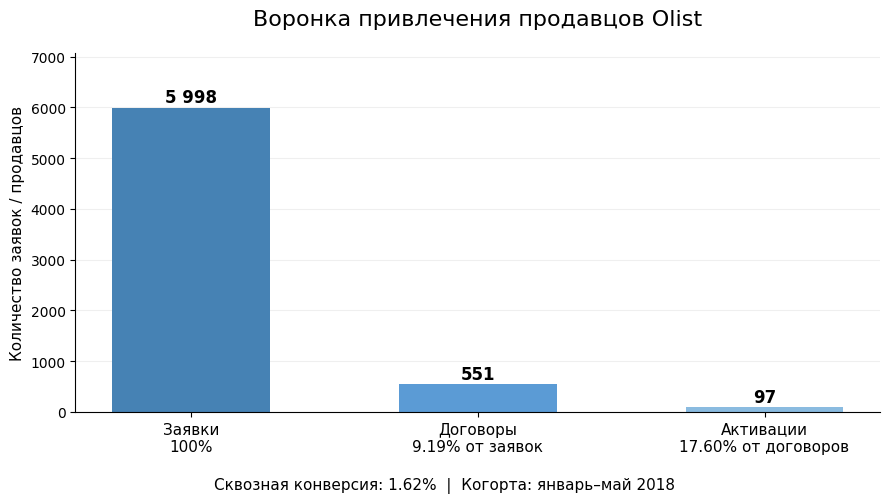

In [59]:
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    categories,
    values,
    color=["#4682B4", "#5B9BD5", "#8ABBE0"],
    width=0.55
)

# Значения над столбцами
for bar, value in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 100,
        f"{value:,}".replace(",", " "),
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

ax.set_title("Воронка привлечения продавцов Olist", fontsize=16, pad=20)
ax.set_ylabel("Количество заявок / продавцов", fontsize=11)
ax.set_ylim(0, max(values) * 1.18)

# Конверсии под названиями этапов
ax.set_xticks(range(3))
ax.set_xticklabels([
    "Заявки\n100%",
    f"Договоры\n{cr_deal:.2f}% от заявок",
    f"Активации\n{cr_activation:.2f}% от договоров"
], fontsize=11)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.5, 0.01,
    f"Сквозная конверсия: {cr_total:.2f}%  |  Когорта: январь–май 2018",
    ha="center",
    fontsize=11
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig("olist_funnel.png", dpi=300, bbox_inches="tight")
plt.show()

In [60]:
df_sorted = df.sort_values(by="total_gmv", ascending=True)

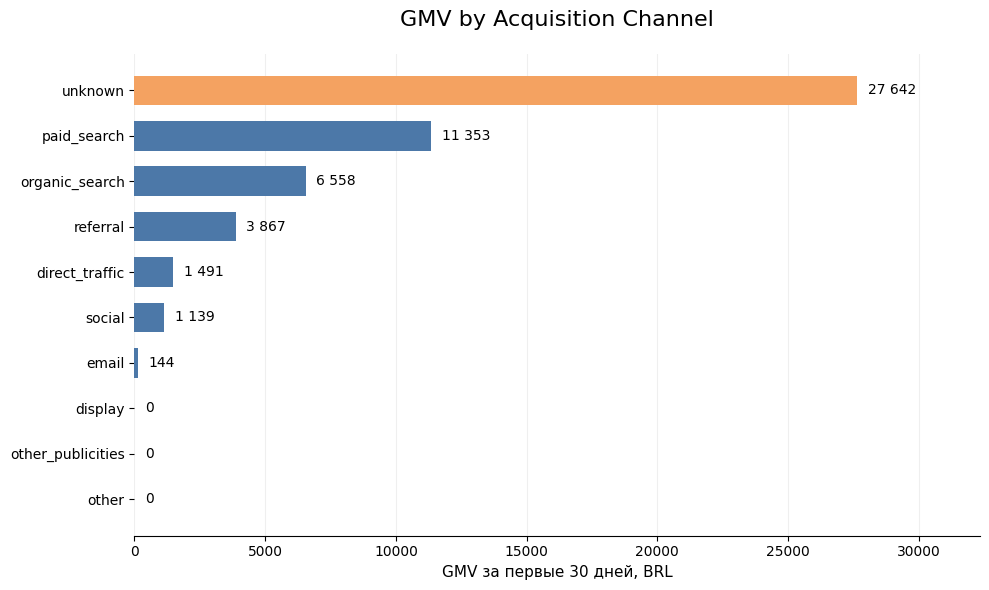

In [61]:
fig, ax = plt.subplots(figsize=(10, 6))

colors = [
    "#F4A261" if origin == "unknown" else "#4C78A8"
    for origin in df_sorted["origin"]
]

bars = ax.barh(
    df_sorted["origin"],
    df_sorted["total_gmv"],
    color=colors,
    height=0.65
)

# Подписи значений
for bar in bars:
    value = bar.get_width()
    ax.text(
        value + 400,
        bar.get_y() + bar.get_height() / 2,
        f"{value:,.0f}".replace(",", " "),
        va="center",
        fontsize=10
    )

ax.set_title("GMV by Acquisition Channel", fontsize=16, pad=20)
ax.set_xlabel("GMV за первые 30 дней, BRL", fontsize=11)
ax.set_ylabel("")
ax.set_xlim(0, df_sorted["total_gmv"].max() * 1.17)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("gmv_by_channel.png", dpi=300, bbox_inches="tight")
plt.show()

In [62]:
df_sc = pd.read_csv("seller_concentration.csv")

In [63]:
df_sc.head()

,origin,total_gmv,top1_gmv,top1_share_pct,top3_share_pct
0,unknown,27642,15418,55.78,81.29
1,paid_search,11353,2496,21.99,53.56
2,organic_search,6558,654,9.97,25.47
3,referral,3867,2288,59.17,86.71
4,direct_traffic,1491,598,40.11,70.36


In [64]:
df_sc_sorted = df_sc.sort_values(by="top3_share_pct", ascending=True)

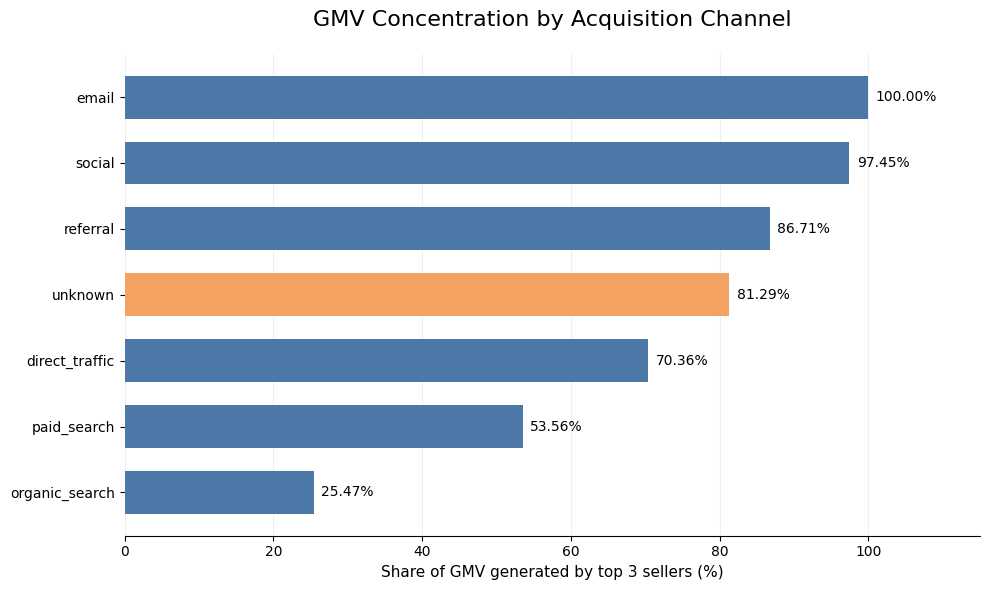

In [65]:
df_sc_sorted = df_sc.dropna(subset=["top3_share_pct"])
df_sc_sorted = df_sc_sorted.sort_values(by="top3_share_pct", ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))

colors = [
    "#F4A261" if origin == "unknown" else "#4C78A8"
    for origin in df_sc_sorted["origin"]
]

bars = ax.barh(
    df_sc_sorted["origin"],
    df_sc_sorted["top3_share_pct"],
    color=colors,
    height=0.65
)

# Подписи процентов
for bar in bars:
    value = bar.get_width()
    ax.text(
        value + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}%",
        va="center",
        fontsize=10
    )

ax.set_title("GMV Concentration by Acquisition Channel", fontsize=16, pad=20)
ax.set_xlabel("Share of GMV generated by top 3 sellers (%)", fontsize=11)
ax.set_ylabel("")
ax.set_xlim(0, 115)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("gmv_concentration.png", dpi=300, bbox_inches="tight")
plt.show()